Blanco Aéreo                           | Vel   | Dist | RCS  | CPA   | Amenaza (TD)
--------------------------------------------------------------------------------
Caso Artículo (Caza Táctico)           | 700   | 20   | 4.0  | 0     | 75.00 / 100
Misil de Crucero / Stealth             | 2200  | 12   | 0.1  | 100   | 92.22 / 100
Aeronave Comercial / Transporte Lejano | 850   | 110  | 9.0  | 8000  | 20.00 / 100
Dron Kamikaze Cercano                  | 250   | 8    | 0.2  | 0     | 75.00 / 100


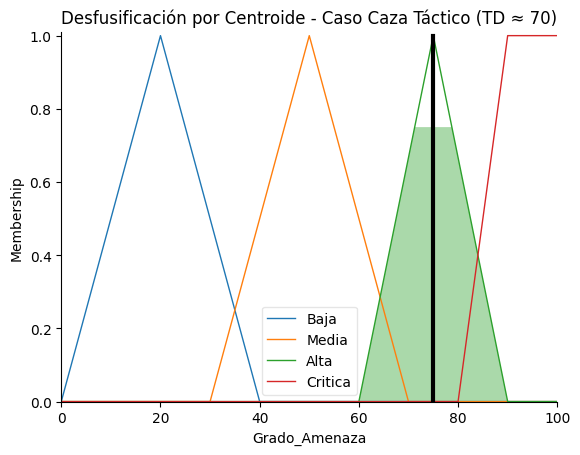

In [ ]:
!pip install -q scikit-fuzzy

import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

# 1. DEFINICIÓN DE UNIVERSOS DE DISCURSO
velocidad = ctrl.Antecedent(np.arange(0, 3001, 10), 'Velocidad_kmh')
distancia = ctrl.Antecedent(np.arange(0, 151, 1), 'Distancia_km')
rcs = ctrl.Antecedent(np.arange(0, 10.1, 0.1), 'RCS_m2')
cpa = ctrl.Antecedent(np.arange(0, 10001, 100), 'CPA_m')

amenaza = ctrl.Consequent(np.arange(0, 101, 1), 'Grado_Amenaza', defuzzify_method='centroid')

# 2. FUNCIONES DE PERTENENCIA (Triangulares y Trapezoidales)
# Velocidad (km/h)
velocidad['Lenta'] = fuzz.trapmf(velocidad.universe, [0, 0, 300, 600])
velocidad['Media'] = fuzz.trimf(velocidad.universe, [400, 800, 1200])
velocidad['Rapida'] = fuzz.trapmf(velocidad.universe, [900, 1500, 3000, 3000])

# Distancia (km)
distancia['Cercana'] = fuzz.trapmf(distancia.universe, [0, 0, 15, 35])
distancia['Media'] = fuzz.trimf(distancia.universe, [20, 50, 80])
distancia['Lejana'] = fuzz.trapmf(distancia.universe, [65, 100, 150, 150])

# RCS - Sección Eficaz de Radar (m^2): Menor RCS = más furtivo (más peligroso)
rcs['Pequena_Stealth'] = fuzz.trapmf(rcs.universe, [0, 0, 0.5, 2.0])
rcs['Media'] = fuzz.trimf(rcs.universe, [1.0, 3.5, 6.0])
rcs['Grande'] = fuzz.trapmf(rcs.universe, [4.5, 7.0, 10.0, 10.0])

# CPA - Punto más cercano de aproximación (m)
cpa['Directo'] = fuzz.trapmf(cpa.universe, [0, 0, 500, 2000])
cpa['Medio'] = fuzz.trimf(cpa.universe, [1000, 3500, 6000])
cpa['Lejano'] = fuzz.trapmf(cpa.universe, [5000, 7500, 10000, 10000])

# Salida: Grado de Amenaza (0 - 100)
amenaza['Baja'] = fuzz.trimf(amenaza.universe, [0, 20, 40])
amenaza['Media'] = fuzz.trimf(amenaza.universe, [30, 50, 70])
amenaza['Alta'] = fuzz.trimf(amenaza.universe, [60, 75, 90])
amenaza['Critica'] = fuzz.trapmf(amenaza.universe, [80, 90, 100, 100])

# 3. BASE DE REGLAS DIFUSAS (Mamdani)
reglas = [
    # Misil de crucero / Caza furtivo a corta distancia en rumbo de colisión
    ctrl.Rule(velocidad['Rapida'] & distancia['Cercana'] & rcs['Pequena_Stealth'] & cpa['Directo'], amenaza['Critica']),
    # Caza convencional (Caso similar al del artículo: Vel=700, Dist=20, RCS=4, CPA=0)
    ctrl.Rule(velocidad['Media'] & distancia['Cercana'] & rcs['Media'] & cpa['Directo'], amenaza['Alta']),
    ctrl.Rule(velocidad['Media'] & distancia['Media'] & rcs['Media'] & cpa['Directo'], amenaza['Media']),
    # Blanco rápido pero a gran distancia o con CPA lejano
    ctrl.Rule(velocidad['Rapida'] & distancia['Lejana'], amenaza['Media']),
    ctrl.Rule(distancia['Lejana'] & cpa['Lejano'], amenaza['Baja']),
    # Blanco lento (ej. helicóptero o UAV grande) a distancia media
    ctrl.Rule(velocidad['Lenta'] & distancia['Media'] & rcs['Grande'], amenaza['Baja']),
    # UAV pequeño/furtivo muy cercano en rumbo directo
    ctrl.Rule(velocidad['Lenta'] & distancia['Cercana'] & rcs['Pequena_Stealth'] & cpa['Directo'], amenaza['Alta'])
]

# 4. CONSTRUCCIÓN Y SIMULACIÓN DEL SISTEMA
sistema_ctrl = ctrl.ControlSystem(reglas)
simulador = ctrl.ControlSystemSimulation(sistema_ctrl)

# Casos de prueba tácticos
casos = [
    {"Nombre": "Caso Artículo (Caza Táctico)", "Vel": 700, "Dist": 20, "RCS": 4.0, "CPA": 0},
    {"Nombre": "Misil de Crucero / Stealth", "Vel": 2200, "Dist": 12, "RCS": 0.1, "CPA": 100},
    {"Nombre": "Aeronave Comercial / Transporte Lejano", "Vel": 850, "Dist": 110, "RCS": 9.0, "CPA": 8000},
    {"Nombre": "Dron Kamikaze Cercano", "Vel": 250, "Dist": 8, "RCS": 0.2, "CPA": 0}
]

print(f"{'Blanco Aéreo':<38} | {'Vel':<5} | {'Dist':<4} | {'RCS':<4} | {'CPA':<5} | {'Amenaza (TD)':<12}")
print("-" * 80)
for c in casos:
    simulador.input['Velocidad_kmh'] = c["Vel"]
    simulador.input['Distancia_km'] = c["Dist"]
    simulador.input['RCS_m2'] = c["RCS"]
    simulador.input['CPA_m'] = c["CPA"]
    simulador.compute()
    td = simulador.output['Grado_Amenaza']
    print(f"{c['Nombre']:<38} | {c['Vel']:<5} | {c['Dist']:<4} | {c['RCS']:<4} | {c['CPA']:<5} | {td:.2f} / 100")

# Visualización del caso del artículo
simulador.input['Velocidad_kmh'] = 700
simulador.input['Distancia_km'] = 20
simulador.input['RCS_m2'] = 4.0
simulador.input['CPA_m'] = 0
simulador.compute()
amenaza.view(sim=simulador)
plt.title("Desfusificación por Centroide - Caso Caza Táctico (TD ≈ 70)")
plt.show()